# 34 插值与拟合

> **模块**：数值方法 ｜ **数据**：`../data/textbook/15.D 导弹.txt` ｜ **依赖**：scipy、numpy、matplotlib

## 1. 问题背景

插值要求曲线通过已知点，拟合只要求整体误差最小。两者常用于数据补全、曲线平滑与经验公式提取，教材中分别给出了一维、二维与多项式情形的算例。

## 2. 学习目标

- 掌握一维与二维插值的使用
- 理解多项式拟合与最小二乘的关系
- 能判断何时用插值、何时用拟合

## 3. 环境与数据

- 依赖：scipy、numpy、matplotlib
- 数据：`../data/textbook/15.D 导弹.txt`

## 4. 方法与实现

### 4.1 插值方法：interp1d 与 CubicSpline

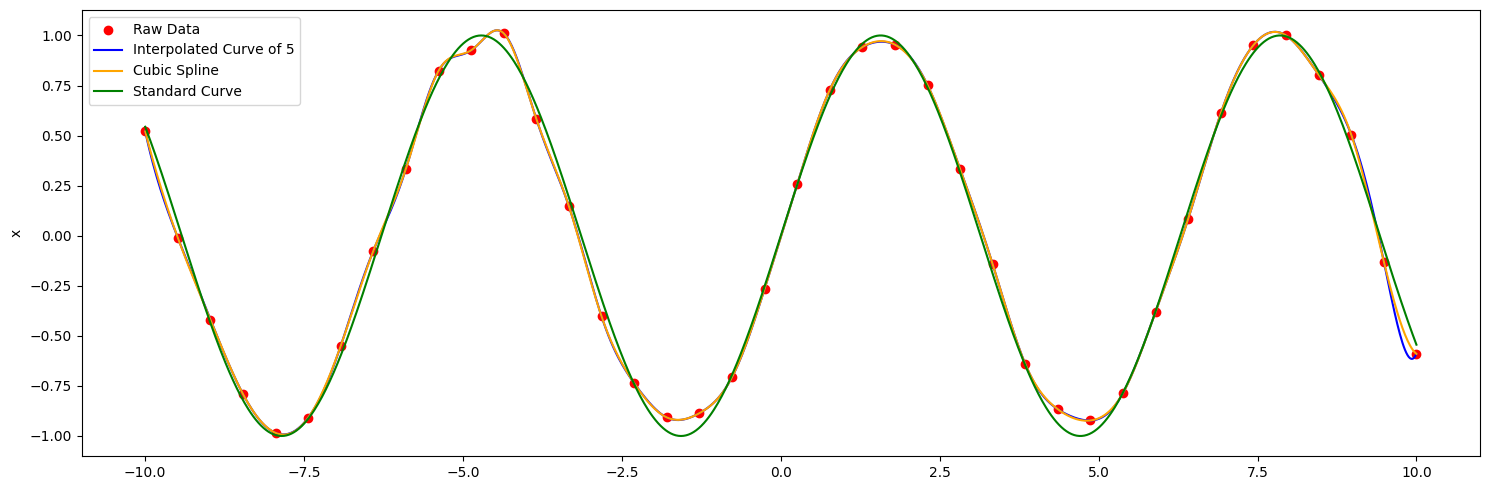

In [1]:
from scipy.optimize import fsolve
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.interpolate import CubicSpline

x = np.linspace(-10, 10, 40)
y = np.sin(x) + np.random.normal(loc=0, scale=0.05, size=x.shape)
xx = np.linspace(-10, 10, 1000)

fig = plt.figure(figsize=(15, 5))
plt.scatter(x, y, c='r', label='Raw Data')
# kind是表示几次插值. 取3时, 与CubicSpline(三次样条插值无边界条件)效果一样
kind = 5
In = interp1d(x, y, kind=kind)
plt.plot(xx, In(xx), c='b', label='Interpolated Curve of {}'.format(kind))
CS = CubicSpline(x, y)
plt.plot(xx, CS(xx), c='orange', label='Cubic Spline')
plt.plot(xx, np.sin(xx), c='g', label='Standard Curve')
plt.ylabel('x')
plt.legend()
plt.tight_layout()
plt.show()

### 4.2 三维插值：导弹轨迹

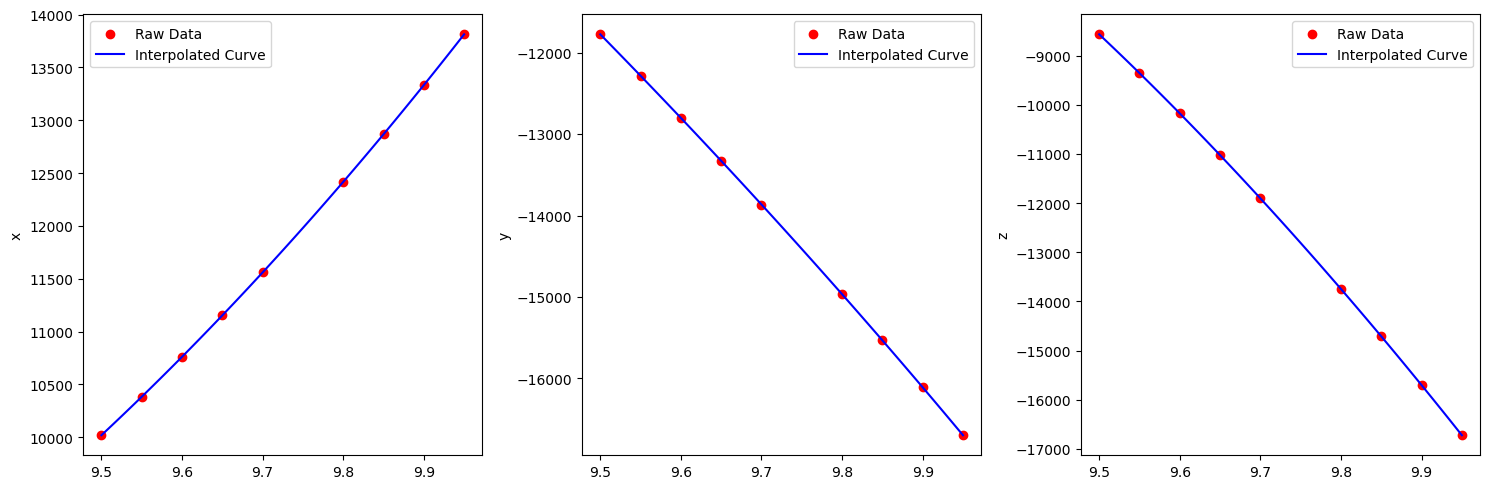

In [2]:
from scipy.optimize import fsolve
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d


def eqs(d):
    return lambda x : [x[0]**2 + x[1]**2 + x[2]**2 - d[0]**2,
                       x[1]**2 + (x[1] - 4500)**2 + x[2]**2 - d[1]**2,
                       (x[0] + 2000)**2 + (x[1] - 1500)**2 + x[2]**2 - d[2]**2]


data = np.loadtxt('../data/textbook/15.D 导弹.txt')
t = data[:,0]
coordinate = np.array([fsolve(eqs(data[i][1:]), [1,1,1]) for i in range(data.shape[0])]).T
t = np.r_[t[:5], t[6:]]
coordinate = np.c_[coordinate[:, :5], coordinate[:, 6:]]

tt = np.linspace(data[:, 0].min(), data[:,0].max(), 100)
fig = plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.scatter(t, coordinate[0], c='r', label='Raw Data')
f = interp1d(t, coordinate[0], kind=3)
plt.plot(tt, f(tt), c='b', label='Interpolated Curve')
plt.ylabel('x')
plt.legend()

plt.subplot(1, 3, 2)
plt.scatter(t, coordinate[1], c='r', label='Raw Data')
f = interp1d(t, coordinate[1], kind=3)
plt.plot(tt, f(tt), c='b', label='Interpolated Curve')
plt.ylabel('y')
plt.legend()

plt.subplot(1, 3, 3)
plt.scatter(t, coordinate[2], c='r', label='Raw Data')
f = interp1d(t, coordinate[2], kind=3)
plt.plot(tt, f(tt), c='b', label='Interpolated Curve')
plt.ylabel('z')
plt.legend() 

plt.tight_layout()
plt.show()

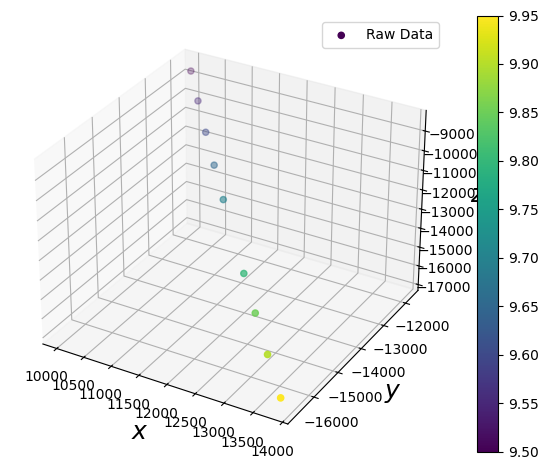

In [3]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(*coordinate, c=t, label='Raw Data')
fig.colorbar(scatter)

tt = np.linspace(data[:, 0].min(), data[:,0].max(), 100)
f = interp1d(t, coordinate[0], kind=3)

# ax.plot_surface(*coordinate, rstride=1, cstride=1, cmap='rainbow')

ax.legend()
ax.set_zlabel(r"$z$", fontsize=18)
ax.set_ylabel(r"$y$", fontsize=18)
ax.set_xlabel(r"$x$", fontsize=18)
ax.legend()
plt.legend()
plt.tight_layout()
plt.show()

## 5. 小结

插值适合精确已知点，拟合适合含噪声数据；多项式阶数过高会出现过拟合，应结合残差判断。

> 内容来源：教材参考实现《数学建模算法与应用》练习稿（MIT，Zhanghan Wang），原始文件已并入本篇，见 `THIRD-PARTY.md`。